In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
from transformers import logging
logging.set_verbosity(50)   # completely silent
import matplotlib.pyplot as plt


import torch
from inference_utils_cltot.data_utils_cltot import (regression_test_metrics,
                                                     bland_altman_plot,
                                                     parity_plot_with_folds,
                                                     parity_plot_with_folds_and_percent,
                                                     )
from inference_cltot import predict_cltot

from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

%load_ext autoreload
%autoreload 2

np.random.seed(30)
torch.manual_seed(0)

In [2]:
data = [('5-Fluorouracil','C1=C(C(=O)NC(=O)N1)F',26.0),
('6-Mercaptopurine','C1=NC2=C(N1)C(=S)N=CN2',15.0),
('7-Hydroxystaurosporine','CC12C(C(CC(O1)N3C4=CC=CC=C4C5=C6C(=C7C8=CC=CC=C8N2C7=C53)C(NC6=O)O)NC)OC',0.00047),
('9-Aminocamptothecin','CCC1(C2=C(COC1=O)C(=O)N3CC4=CC5=C(C=CC=C5N=C4C3=C2)N)O',6.5),
('Abacavir','C1CC1NC2=C3C(=NC(=N2)N)N(C=N3)C4CC(C=C4)CO',13.0),
('Acecainide','CCN(CC)CCNC(=O)C1=CC=C(C=C1)NC(=O)C',4.0),
('Acetaminophen','CC(=O)NC1=CC=C(C=C1)O',5.0),
('Acetazolamide','CC(=O)NC1=NN=C(S1)S(=O)(=O)N',0.64999998),
('Acetylsalicylic Acid','CC(=O)OC1=CC=CC=C1C(=O)O',12.0),
('Acivicin','C1C(ON=C1Cl)C(C(=O)O)N',0.69),
('Actisomide','CC1=NC(=O)C(C2N1CCCC2)(CCN(C(C)C)C(C)C)C3=CC=CC=C3',6.79),
('Acyclovir','C1=NC2=C(N1COCCO)N=C(NC2=O)N',4.6999998),
('Adefovir','C1=NC(=C2C(=N1)N(C=N2)CCOCP(=O)(O)O)N',3.7),
('Albuterol','CC(C)(C)NCC(C1=CC(=C(C=C1)O)CO)O',7.8000002),
('Alfentanil','CCC(=O)N(C1=CC=CC=C1)C2(CCN(CC2)CCN3C(=O)N(N=N3)CC)COC',3.9000001),
('Allopurinol','C1=NNC2=C1C(=O)NC=N2',11.0),]
data_df = pd.DataFrame(data=data, columns=['Name', 'smiles', 'y_true'])
smis = data_df['smiles'].tolist()
y_true = data_df['y_true'].apply(np.log10)

In [3]:
smis

['C1=C(C(=O)NC(=O)N1)F',
 'C1=NC2=C(N1)C(=S)N=CN2',
 'CC12C(C(CC(O1)N3C4=CC=CC=C4C5=C6C(=C7C8=CC=CC=C8N2C7=C53)C(NC6=O)O)NC)OC',
 'CCC1(C2=C(COC1=O)C(=O)N3CC4=CC5=C(C=CC=C5N=C4C3=C2)N)O',
 'C1CC1NC2=C3C(=NC(=N2)N)N(C=N3)C4CC(C=C4)CO',
 'CCN(CC)CCNC(=O)C1=CC=C(C=C1)NC(=O)C',
 'CC(=O)NC1=CC=C(C=C1)O',
 'CC(=O)NC1=NN=C(S1)S(=O)(=O)N',
 'CC(=O)OC1=CC=CC=C1C(=O)O',
 'C1C(ON=C1Cl)C(C(=O)O)N',
 'CC1=NC(=O)C(C2N1CCCC2)(CCN(C(C)C)C(C)C)C3=CC=CC=C3',
 'C1=NC2=C(N1COCCO)N=C(NC2=O)N',
 'C1=NC(=C2C(=N1)N(C=N2)CCOCP(=O)(O)O)N',
 'CC(C)(C)NCC(C1=CC(=C(C=C1)O)CO)O',
 'CCC(=O)N(C1=CC=CC=C1)C2(CCN(CC2)CCN3C(=O)N(N=N3)CC)COC',
 'C1=NNC2=C1C(=O)NC=N2']

In [4]:
smis[2]

'CC12C(C(CC(O1)N3C4=CC=CC=C4C5=C6C(=C7C8=CC=CC=C8N2C7=C53)C(NC6=O)O)NC)OC'

In [5]:
y_pred = predict_cltot(smis)

In [6]:
y_pred[2]

{'smiles': 'CC12C(C(CC(O1)N3C4=CC=CC=C4C5=C6C(=C7C8=CC=CC=C8N2C7=C53)C(NC6=O)O)NC)OC',
 'NN': -1.1159,
 'RF': -0.0314,
 'SVM': -0.4875,
 'XGB': -0.2308,
 'image': '<?xml version="1.0" encoding="utf-8" standalone="no"?>\n<!DOCTYPE svg PUBLIC "-//W3C//DTD SVG 1.1//EN"\n  "http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd">\n<svg xmlns:xlink="http://www.w3.org/1999/xlink" width="568.8pt" height="568.8pt" viewBox="0 0 568.8 568.8" xmlns="http://www.w3.org/2000/svg" version="1.1">\n <metadata>\n  <rdf:RDF xmlns:dc="http://purl.org/dc/elements/1.1/" xmlns:cc="http://creativecommons.org/ns#" xmlns:rdf="http://www.w3.org/1999/02/22-rdf-syntax-ns#">\n   <cc:Work>\n    <dc:type rdf:resource="http://purl.org/dc/dcmitype/StillImage"/>\n    <dc:date>2026-11-04T13:21:37.333302</dc:date>\n    <dc:format>image/svg+xml</dc:format>\n    <dc:creator>\n     <cc:Agent>\n      <dc:title>Matplotlib v3.9.2, https://matplotlib.org/</dc:title>\n     </cc:Agent>\n    </dc:creator>\n   </cc:Work>\n  </rdf:RDF>\n <

In [7]:
y_pred[0]

{'smiles': 'C1=C(C(=O)NC(=O)N1)F',
 'NN': 0.8253,
 'RF': 0.6062,
 'SVM': 0.7385,
 'XGB': 0.6215,
 'image': '<?xml version="1.0" encoding="utf-8" standalone="no"?>\n<!DOCTYPE svg PUBLIC "-//W3C//DTD SVG 1.1//EN"\n  "http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd">\n<svg xmlns:xlink="http://www.w3.org/1999/xlink" width="568.8pt" height="568.8pt" viewBox="0 0 568.8 568.8" xmlns="http://www.w3.org/2000/svg" version="1.1">\n <metadata>\n  <rdf:RDF xmlns:dc="http://purl.org/dc/elements/1.1/" xmlns:cc="http://creativecommons.org/ns#" xmlns:rdf="http://www.w3.org/1999/02/22-rdf-syntax-ns#">\n   <cc:Work>\n    <dc:type rdf:resource="http://purl.org/dc/dcmitype/StillImage"/>\n    <dc:date>2026-11-04T13:21:37.111265</dc:date>\n    <dc:format>image/svg+xml</dc:format>\n    <dc:creator>\n     <cc:Agent>\n      <dc:title>Matplotlib v3.9.2, https://matplotlib.org/</dc:title>\n     </cc:Agent>\n    </dc:creator>\n   </cc:Work>\n  </rdf:RDF>\n </metadata>\n <defs>\n  <style type="text/css">*{stroke-l

In [ ]:
y_pred[0]

{'smiles': 'C1=C(C(=O)NC(=O)N1)F',
 'NN': 0.8253,
 'RF': 0.6062,
 'SVM': 0.7385,
 'XGB': 0.6215,
 'image': '<?xml version="1.0" encoding="utf-8" standalone="no"?>\n<!DOCTYPE svg PUBLIC "-//W3C//DTD SVG 1.1//EN"\n  "http://www.w3.org/Graphics/SVG/1.1/DTD/svg11.dtd">\n<svg xmlns:xlink="http://www.w3.org/1999/xlink" width="568.8pt" height="568.8pt" viewBox="0 0 568.8 568.8" xmlns="http://www.w3.org/2000/svg" version="1.1">\n <metadata>\n  <rdf:RDF xmlns:dc="http://purl.org/dc/elements/1.1/" xmlns:cc="http://creativecommons.org/ns#" xmlns:rdf="http://www.w3.org/1999/02/22-rdf-syntax-ns#">\n   <cc:Work>\n    <dc:type rdf:resource="http://purl.org/dc/dcmitype/StillImage"/>\n    <dc:date>2026-08-13T20:01:30.931979</dc:date>\n    <dc:format>image/svg+xml</dc:format>\n    <dc:creator>\n     <cc:Agent>\n      <dc:title>Matplotlib v3.9.2, https://matplotlib.org/</dc:title>\n     </cc:Agent>\n    </dc:creator>\n   </cc:Work>\n  </rdf:RDF>\n </metadata>\n <defs>\n  <style type="text/css">*{stroke-l

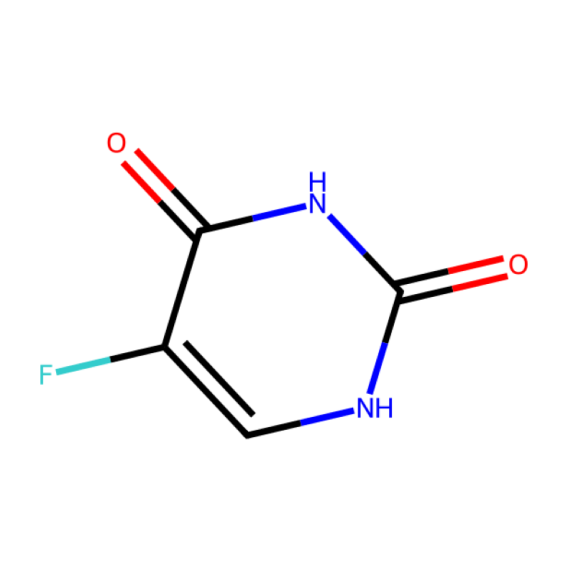

In [ ]:
from IPython.display import SVG, display

display(SVG(y_pred[0]['image']))
# df = pd.DataFrame(y_pred)
# df['true'] = y_true.to_numpy()
# df
# y_pred

In [ ]:
# from transformers import AutoTokenizer, AutoModel, AutoConfig

# # model_name = "DeepChem/ChemBERTa-77M-MLM"
# local_path = "/home/rkmvu/Test_inferencec_files_Teoreler/Inference_CLtot/Best_models/ChemBert/repr_model/"

# # tokenizer = AutoTokenizer.from_pretrained(model_name)
# # model = AutoModel.from_pretrained(model_name)

# # tokenizer.save_pretrained(local_path)
# # model.save_pretrained(local_path)

In [ ]:

# tokenizer = AutoTokenizer.from_pretrained(local_path, local_files_only=True)
# model = AutoModel.from_pretrained(local_path, local_files_only=True)
# config = AutoConfig.from_pretrained(local_path)
# config

In [ ]:
# import os, pickle
# import xgboost as xgb

# root = "/home/rkmvu/Test_inferencec_files_Teoreler/Inference_CLtot/Best_models"

# for dirpath, dirnames, filenames in os.walk(root):
#     for filename in filenames:
#         if filename.endswith("_xgb_best_model.pkl"):
#             filepath = os.path.join(dirpath, filename)
#             print(filepath)
#             # Load the pickle model
#             with open(filepath, "rb") as f:
#                 model = pickle.load(f)
#             # print("Loaded model type:", type(model))
#             output_file = filepath.replace('.pkl', '.json')
#             print(output_file)

#             # Save as native XGBoost JSON
#             if isinstance(model, xgb.XGBModel):
#                 model.save_model(output_file)

#             elif isinstance(model, xgb.Booster):
#                 model.save_model(output_file)